<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_35_Raw_and_Softmax_attention_scores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import torch
from transformers import AutoModelForCausalLM, GPT2Tokenizer
import torch.nn.functional as F

# Part 1: The reason to scale by sqrt(d_h)

## Task_1:
- In a for-loop over integers from N = 5 to N = 100, create two
N ×N matrices of Gaussian random numbers, and multiply them
together. Use standard matrix multiplication with the @ symbol, not
element-wise multiplication with the * symbol.
Create a second matrix defined as the product matrix scaled
by √N. Calculate and plot the standard deviations as in Figure
6.20. Then draw a line corresponding to the square root of the
matrix sizes.

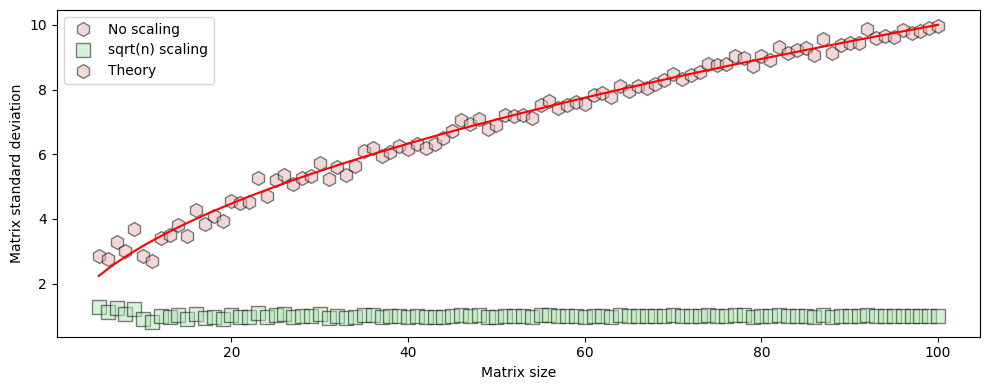

In [11]:

matsizes = np.arange(5,101)

plt.figure(figsize=(10,4))

for n in matsizes:

  # create the matrices
  M1 = np.random.randn(n,n) @ np.random.randn(n,n)
  M2 = M1 / np.sqrt(n)

  # plot
  plt.plot(n,M1.std(),'kh',markerfacecolor=[.9,.7,.7,.5],markersize=10)
  plt.plot(n,M2.std(),'ks',markerfacecolor=[.7,.9,.7,.5],markersize=10)



plt.plot(matsizes,np.sqrt(matsizes),'r')
plt.gca().set(xlabel='Matrix size',ylabel='Matrix standard deviation')
plt.legend(['No scaling','sqrt(n) scaling','Theory'])

plt.tight_layout()
plt.show()

# Part_2:Model,tokens,QKV Activations

## Task_1:
- Import GPT-2-medium. Implant a hook function into the c_attn
layer of transformer 6, that stores the activations in a dictionary.
Store the hook handle so it can be removed later.
Tokenize the text about the color purple that is in the online
code file. Push the tokens through the model and confirm that the
size of the attention activations is 1 × 115 × 3072

In [12]:
# load GPT2 model and tokenizer
model = AutoModelForCausalLM.from_pretrained('gpt2-medium')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

model.eval()

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1024)
    (wpe): Embedding(1024, 1024)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPT2Block(
        (ln_1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3072, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=1024)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=4096, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=4096)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1024, out_features=50257, bias=False)
)

In [13]:
# hook the attention vectors
activations = {}

def hook(module,input,output):
  activations[keyName] = output.detach()

# implant the hooks
whichlayer = 6
keyName = f'attn_{whichlayer}'
hookhandle = model.transformer.h[whichlayer].attn.c_attn.register_forward_hook(hook)

In [25]:
# https://en.wikipedia.org/wiki/Purple
txt = "Purple is a color similar in appearance to violet light. In the RYB color model historically used in the arts, purple is a secondary color created by combining red and blue pigments. In the CMYK color model used in modern printing, purple is made by combining magenta pigment with either cyan pigment, black pigment, or both. In the RGB color model used in computer and television screens, purple is created by mixing red and blue light in order to create colors that appear similar to violet light. According to color theory, purple is considered a cool color."

# tokenize
tokens = tokenizer.encode(txt,return_tensors='pt')
ntokens =len(tokens[0])

# run through the model
with torch.no_grad():
  model(tokens)

In [26]:

# checking sizes
print(activations.keys())
print(activations[keyName].shape)

dict_keys(['attn_6'])
torch.Size([1, 115, 3072])


In [27]:
activations

{'attn_6': tensor([[[ 0.2274,  0.1474,  0.0110,  ...,  0.0260,  0.0559,  0.0257],
          [-0.4611, -1.7914,  0.2417,  ...,  0.1127,  0.6776, -0.7316],
          [ 0.0039, -0.1152, -0.5475,  ...,  0.4973, -0.2862, -1.3271],
          ...,
          [ 0.4443, -0.2666,  1.3602,  ...,  0.5379,  0.5546,  0.2758],
          [ 1.7429, -0.8359,  0.8308,  ..., -0.4077,  0.4291,  0.4087],
          [ 0.1460,  0.1959,  1.2098,  ..., -0.5595,  0.0646,  0.8506]]])}

In [20]:
model.transformer.h[6].attn.c_attn

Conv1D(nf=3072, nx=1024)

# Part 3: Split into heads

## Task_1:
- Define variables for the number of layers, the embeddings dimen
sionality, the number of heads, the head dimensionality, and √dh.
Confirm that there are 16 heads, each with 64 dimensions.
Separate the activations matrix from Part 2 into the queries,
keys, and values matrices, and then split the Q and K matrices
further into lists of heads.
Show the activations heatmaps from all Q heads as in Figure
6.21. The x-axis shows token positions and the y-axis shows the
head dimensionality. This is similar to the figure from Project 34
but you’ll need to modify the code to account for the different data
organization

In [28]:

# some helpful variables
n_layers = model.config.n_layer
n_emb = model.config.n_embd
n_heads = model.config.n_head
head_dim = model.config.n_embd //n_heads
sqrtD =head_dim ** .5

print(f'There are {n_heads} heads, each with {head_dim} dimensions.')

There are 16 heads, each with 64 dimensions.


In [31]:
activations[keyName]

tensor([[[ 0.2274,  0.1474,  0.0110,  ...,  0.0260,  0.0559,  0.0257],
         [-0.4611, -1.7914,  0.2417,  ...,  0.1127,  0.6776, -0.7316],
         [ 0.0039, -0.1152, -0.5475,  ...,  0.4973, -0.2862, -1.3271],
         ...,
         [ 0.4443, -0.2666,  1.3602,  ...,  0.5379,  0.5546,  0.2758],
         [ 1.7429, -0.8359,  0.8308,  ..., -0.4077,  0.4291,  0.4087],
         [ 0.1460,  0.1959,  1.2098,  ..., -0.5595,  0.0646,  0.8506]]])

In [35]:

# first, separate the Q,K,V matrices
Q,K,V = torch.split(activations[keyName][0,:,:],n_emb,dim=1)
Q.shape

torch.Size([115, 1024])

In [36]:
# now split into heads
Q_h = torch.split(Q,head_dim,dim=1)
K_h = torch.split(K,head_dim,dim=1)

print(f'There are {len(Q_h)} heads')
print(f'Each head has size {Q_h[2].shape}')

There are 16 heads
Each head has size torch.Size([115, 64])


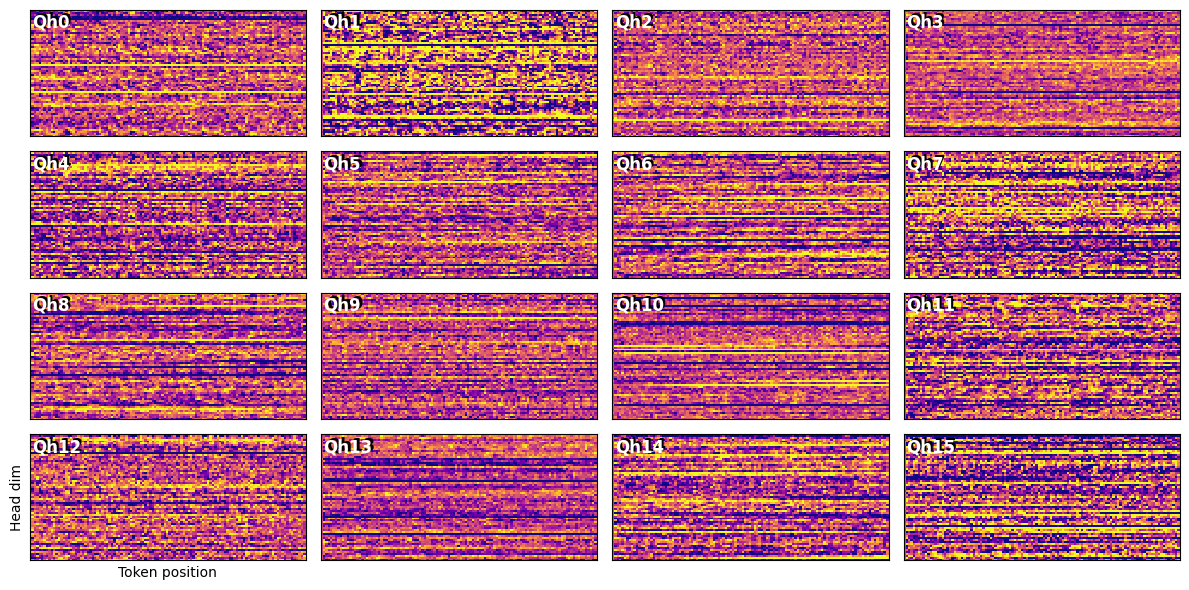

In [43]:

# visualize
_,axs = plt.subplots(4,4,figsize=(12,6))

for i,ax in enumerate(axs.flatten()):
  ax.pcolor(Q_h[i].T,cmap='plasma',vmin=-2,vmax=2)
  ax.text(2,head_dim-1,f'Qh{i}',fontsize=12,fontweight='bold',color='k',ha='left',va='top')
  ax.text(1,head_dim-2,f'Qh{i}',fontsize=12,fontweight='bold',color='w',ha='left',va='top')
  ax.set(xticks=[],yticks=[])

# finalize
axs[3,0].set(ylabel='Head dim',xlabel='Token position')

plt.tight_layout()
plt.show()

# Part 4: Raw attention scores in one layer

## Task_1:
- Create a double for-loop over the 16 heads. For each pair of heads
(i, j), calculate QiKj⊤/√hd, but only for the scores of the final
token in Q with all previous tokens in K excluding the first token.
Store the resulting attention scores in one of two vectors, depending
on whether the dot products are calculated between Q and K from
within the same head (that is, when i = j) vs. across different heads
(when i ̸ = j).
The dot products are PyTorch tensors, but store the results in
NumPy arrays.
Report the number of dot products for the within vs. across
heads pairs. What implication does the sample size counts have for
creating and comparing histograms?
Show the results in violin and scatter plots as in Figure 6.22A
(include random x-axis jitter to highlight the variability), and show
the distributions of dot products as in Figure 6.22B.

In [62]:

# initializations
withinhead_dp = np.array([])
acrosshead_dp = np.array([])

# loop over pairs of heads
for qi in range(n_heads):
  for ki in range(n_heads):

    # dot product for last token in Q with all previous tokens in K (excluding first token)
    dp = Q_h[qi][-1,:] @ K_h[ki][1:-1,:].t() / sqrtD
    dp = dp.numpy() # numpy will convert from pytorch, but this is cleaner

    # store in the appropriate matrix
    if qi==ki:
      withinhead_dp = np.concatenate((withinhead_dp,dp))
    else:
      acrosshead_dp = np.concatenate((acrosshead_dp,dp))

print(f'There are {len(acrosshead_dp)} values in "across head"')
print(f'      and {len(withinhead_dp):5} values in "within head".')

There are 27120 values in "across head"
      and  1808 values in "within head".


In [61]:
K_h[15][1:-1,:].shape

torch.Size([113, 64])

In [60]:
K_h[15].shape

torch.Size([115, 64])

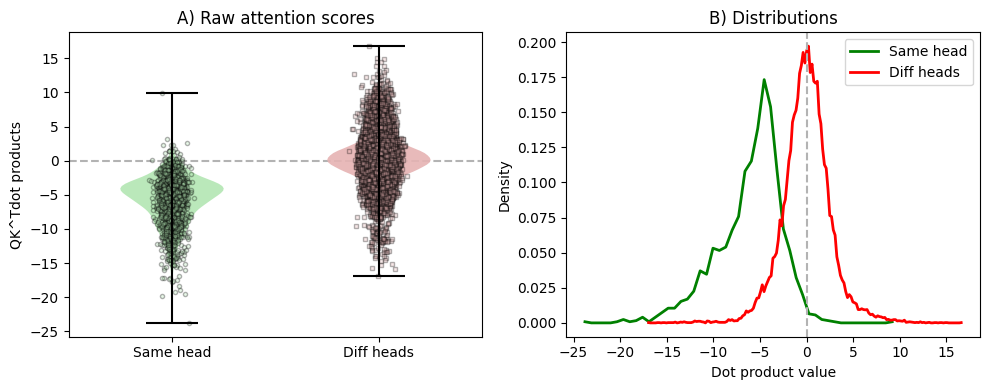

In [64]:

## visualizations
_,axs = plt.subplots(1,2,figsize=(10,4))

# plot the raw data
axs[0].plot(np.random.normal(1,1/30,len(withinhead_dp)),withinhead_dp,'ko',linewidth=.1,markerfacecolor=[.7,.9,.7,.3],markersize=3)
axs[0].plot(np.random.normal(2,1/30,len(acrosshead_dp)),acrosshead_dp,'ks',linewidth=.1,markerfacecolor=[.9,.7,.7,.3],markersize=3)

# and the violin plot
v = axs[0].violinplot([withinhead_dp,acrosshead_dp])

# change the colors
v['bodies'][0].set_facecolor([.7,.9,.7])
v['bodies'][1].set_facecolor([.9,.7,.7])
v['bodies'][0].set_alpha([.9])
v['bodies'][1].set_alpha([.9])
v['cbars'].set_edgecolor('k')
v['cmins'].set_edgecolor('k')
v['cmaxes'].set_edgecolor('k')

axs[0].axhline(0,linestyle='--',color=[.7,.7,.7],zorder=-3)
axs[0].set(xticks=[1,2],xticklabels=['Same head','Diff heads'],
  ylabel='QK^Tdot products',title='A) Raw attention scores',xlim=[.5,2.5])


# distributions
y,x = np.histogram(withinhead_dp,bins='fd',density=True)
axs[1].plot(x[:-1],y,'g',linewidth=2,label='Same head')

y,x = np.histogram(acrosshead_dp,bins='fd',density=True)
axs[1].plot(x[:-1],y,'r',linewidth=2,label='Diff heads')

axs[1].legend()
axs[1].set(xlabel='Dot product value',ylabel='Density',title='B) Distributions')
axs[1].axvline(0,linestyle='--',color=[.7,.7,.7])

plt.tight_layout()
plt.show()

# Part 5: Attention score distributions over layers

## Task_1:
- Remove the hook that you installed in Part 2. Implant a new set of
hooks that is the same as in Part 2 but for all layers.
Run the same tokens through the model, and confirm that the
activations dictionary now contains 24 keys.
Repeat the dot products and histogram analysis from Part 4
but in an additional for-loop over all the layers. Use bin boundaries
of-20 to 20 in 101 steps, for all histograms in all layers. Store the
histogram density values in a 3D array of size layers × pair type
(within vs. across head) × histogram bins. Visualize the histograms
as heatmaps as in Figure 6.23.

In [65]:
hookhandle.remove()

In [67]:
# hook the attention vectors
activations = {}

def implant_hook(layer_number):
  def hook(module, input, output):
    activations[f'attn_L{layer_number}'] =output.detach()
  return hook

# implant the hooks
handles = []
for i in range(n_layers):
  h = model.transformer.h[i].attn.c_attn.register_forward_hook(implant_hook(i))
  handles.append(h)


In [66]:
n_layers

24

In [68]:
# run through the model
with torch.no_grad():
  model(tokens)

In [69]:
handles

In [70]:
activations

{'attn_L0': tensor([[[ 6.1854e-01, -6.0990e-01, -5.1753e-02,  ...,  4.4571e-03,
            1.6006e-04, -2.2196e-02],
          [ 6.1414e-01, -4.2269e-01, -8.8686e-01,  ..., -9.7141e-03,
            4.9409e-02, -4.3364e-02],
          [-1.0005e-01, -9.5825e-01, -9.8493e-01,  ..., -3.2487e-02,
            1.8408e-02,  4.4735e-02],
          ...,
          [ 7.5703e-01, -4.3479e-01,  3.2744e-01,  ...,  3.7846e-02,
            1.3290e-01, -8.1128e-03],
          [ 8.8516e-01, -3.9993e-01,  1.4662e-01,  ...,  1.5406e-02,
           -8.1123e-03, -5.0084e-02],
          [ 3.3002e-01, -5.2227e-01, -3.9101e-01,  ...,  4.4457e-03,
           -6.0610e-03,  6.9546e-04]]]),
 'attn_L1': tensor([[[ 0.6917,  0.1810,  0.7202,  ..., -0.0532,  0.2662, -0.1211],
          [ 0.8129,  0.4066,  0.7092,  ...,  1.0903, -0.2955, -0.0144],
          [ 0.9462,  0.3200,  0.3253,  ...,  0.2961, -0.0801,  0.0779],
          ...,
          [ 0.1735,  0.0295,  0.0283,  ..., -0.2951,  2.1223,  0.2041],
          [ 0.4

In [73]:
activations.keys()

dict_keys(['attn_L0', 'attn_L1', 'attn_L2', 'attn_L3', 'attn_L4', 'attn_L5', 'attn_L6', 'attn_L7', 'attn_L8', 'attn_L9', 'attn_L10', 'attn_L11', 'attn_L12', 'attn_L13', 'attn_L14', 'attn_L15', 'attn_L16', 'attn_L17', 'attn_L18', 'attn_L19', 'attn_L20', 'attn_L21', 'attn_L22', 'attn_L23'])

In [74]:
histedges = np.linspace(-20,20,101)

layerHists = np.zeros((n_layers,2,len(histedges)-1))


# loop over layers
for layeri in range(n_layers):

  # get the activations
  Q,K,V = torch.split(activations[f'attn_L{layeri}'][0,:,:],n_emb,dim=1)
  Q_h = torch.split(Q,head_dim,dim=1)
  K_h = torch.split(K,head_dim,dim=1)


  # re-initialize
  withinhead_dp = np.array([])
  acrosshead_dp = np.array([])

  # loop over pairs of heads
  for qi in range(n_heads):
    for ki in range(n_heads):

      # dot product for last token in Q with all previous tokens in K (excluding first token)
      dp = Q_h[qi][-1,:] @ K_h[ki][1:-1,:].t() / sqrtD
      dp = dp.numpy() # pytorch -> numpy

      # store in the appropriate matrix
      if qi==ki:
        withinhead_dp = np.concatenate((withinhead_dp,dp))
      else:
        acrosshead_dp = np.concatenate((acrosshead_dp,dp))


  # distributions
  y,_ = np.histogram(withinhead_dp,bins=histedges,density=True)
  layerHists[layeri,0,:] = y

  y,_ = np.histogram(acrosshead_dp,bins=histedges,density=True)
  layerHists[layeri,1,:] = y


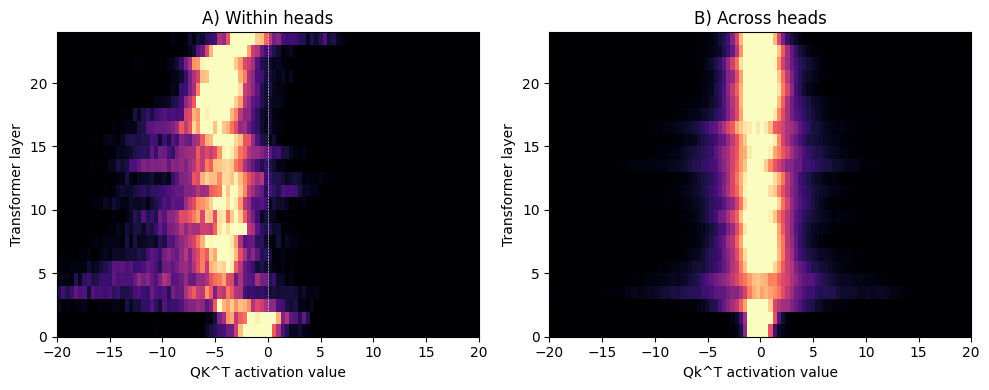

In [75]:

_,axs = plt.subplots(1,2,figsize=(10,4))
axs[0].imshow(layerHists[:,0,:],origin='lower',aspect='auto',cmap='magma',
              extent=[histedges[0],histedges[-1],0,n_layers],vmin=0,vmax=.15)
axs[0].axvline(0,linestyle='--',color='w',linewidth=.4)

axs[1].imshow(layerHists[:,1,:],origin='lower',aspect='auto',cmap='magma',
              extent=[histedges[0],histedges[-1],0,n_layers],vmin=0,vmax=.15)

axs[0].set(xlabel='QK^T activation value',ylabel='Transformer layer',title='A) Within heads')
axs[1].set(xlabel='Qk^T activation value',ylabel='Transformer layer',title='B) Across heads')

plt.tight_layout()
plt.show()

## Task_2:
- Calculate the mean and standard deviation across layers for each pair
category. Visualize the results as lines corresponding to the layer
averaged density, and the areas around the lines corresponding to
one standard deviation above and below the line. See in Figure 6.24.

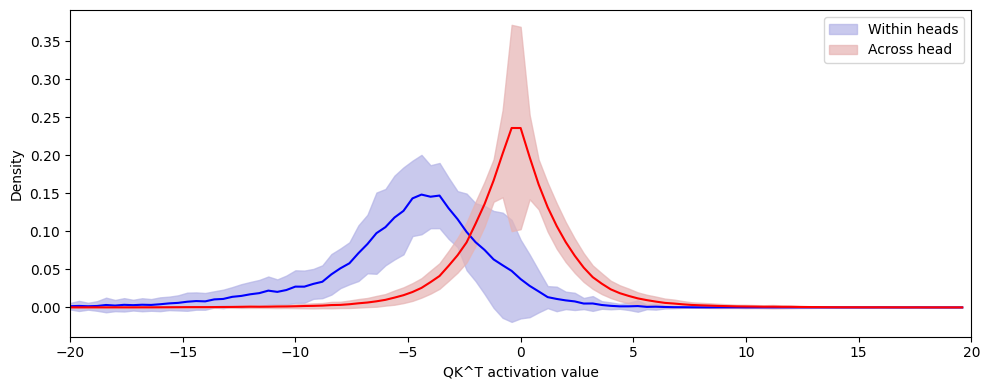

In [76]:

# get the means and standard deviations
y0  = layerHists[:,0,:].mean(axis=0)
y0e = layerHists[:,0,:].std(axis=0)
y1  = layerHists[:,1,:].mean(axis=0)
y1e = layerHists[:,1,:].std(axis=0)

plt.figure(figsize=(10,4))

plt.fill_between(histedges[:-1],y0-y0e,y0+y0e,color=[.7,.7,.9,.7],label='Within heads')
plt.plot(histedges[:-1],y0,'b')
plt.fill_between(histedges[:-1],y1-y1e,y1+y1e,color=[.9,.7,.7,.7],label='Across head')
plt.plot(histedges[:-1],y1,'r')

plt.legend()
plt.gca().set(xlabel='QK^T activation value',ylabel='Density',xlim=histedges[[0,-1]])

plt.tight_layout()
plt.show()

# Part 6: Laminar distributions of raw and softmax scores

## Task_1:
- In a for-loop over transformer layers, split the layer-specific hooked
activations into Q, K, and V, and then reshape Q and K to have a
head dimension in the tensors. This is the head-separating approach
taken in Project 34 as opposed to the split function you’ve used so
far here in Project 35.
Calculate the softmax attention scores. You need to permute
the Q and K tensors such that the order of dimensions is batch ×
head × tokens × head-dimension. Then calculate QK⊤ using the
.transpose method on K to transpose the final two dimensions
(tokens and head-dimension).
Calculate and visualize the mean of the QK⊤ raw scores as in
Figure 6.25A, the histogram of the raw scores as in Figure 6.25B
(using 200 histogram bins between-15 and 15), and the histogram
of the softmax attention scores as in Figure 6.25C. Note that the
F.softmax function works only on PyTorch tensors, not on NumPy
arrays. Therefore, you should run these analysis using PyTorch
functions instead of NumPy functions.

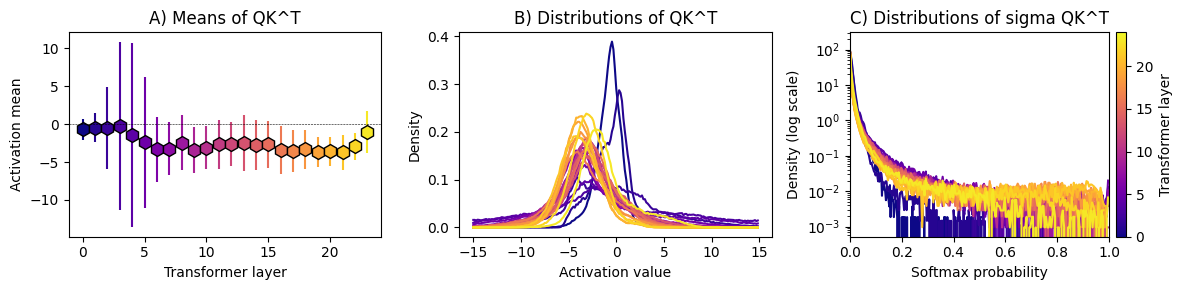

In [77]:
_,axs = plt.subplots(1,3,figsize=(12,3))


# normalization for mapping line colors to colorbar
cmap = plt.cm.plasma
norm = mpl.colors.Normalize(vmin=0,vmax=n_layers)


# loop over all the layers
for layeri in range(n_layers):

  # split the matrices
  Q,K,V = torch.split(activations[f'attn_L{layeri}'],n_emb,dim=-1)

  # calculate the attention activations
  Qh = Q.view(1,ntokens,n_heads,head_dim).permute(0,2,1,3)
  Kh = K.view(1,ntokens,n_heads,head_dim).permute(0,2,1,3)
  qkt = (Qh @ Kh.transpose(-2,-1)) / sqrtD

  # plot the average QK^T scores
  axs[0].errorbar(layeri,qkt.mean(),qkt.std(),color=plt.cm.plasma(layeri/n_layers))
  axs[0].plot(layeri,qkt.mean(),'kh',markersize=10,
              markerfacecolor=plt.cm.plasma(layeri/n_layers))

  # distribution of "raw" values
  y,x = torch.histogram(qkt.flatten(),torch.linspace(-15,15,201),density=True)
  axs[1].plot(x[:-1],y,color=cmap(norm(layeri)),label=f'Layer {layeri}')

  # distribution of softmax-prob values
  y,x = torch.histogram(F.softmax(qkt,dim=-1).flatten(),201,density=True)
  axs[2].plot(x[:-1],y,color=plt.cm.plasma(layeri/n_layers),label=f'Layer {layeri}')


# plot adjustments
axs[0].axhline(0,color='k',linestyle='--',linewidth=.4)
axs[0].set(xlabel='Transformer layer',ylabel='Activation mean',title='A) Means of QK^T')
axs[1].set(xlabel='Activation value',ylabel='Density',title='B) Distributions of QK^T')
axs[2].set(xlabel='Softmax probability',ylabel='Density (log scale)',yscale='log',xlim=[0,1],
           title='C) Distributions of sigma QK^T')

# create a colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap,norm=norm)
cbar = plt.colorbar(sm,ax=axs[-1],pad=.02)
cbar.set_label('Transformer layer')

plt.tight_layout()

plt.show()



# Part 7: Softmax probabilities for self- vs. cross-attention

## Task_1:
- Create a causal mask for a sequence of five tokens. First, create a
5×5 triangular PyTorch tensor of ones above the diagonal and zeros
on and below, and visualize as in Figure 6.26A. Second, modify that
mask to turn the ones into −∞ (use torch.inf) and visualize as in
Figure 6.26B. Finally, apply the softmax transform across the rows
to produce Figure 6.26C. Use the same color scaling for all panels.

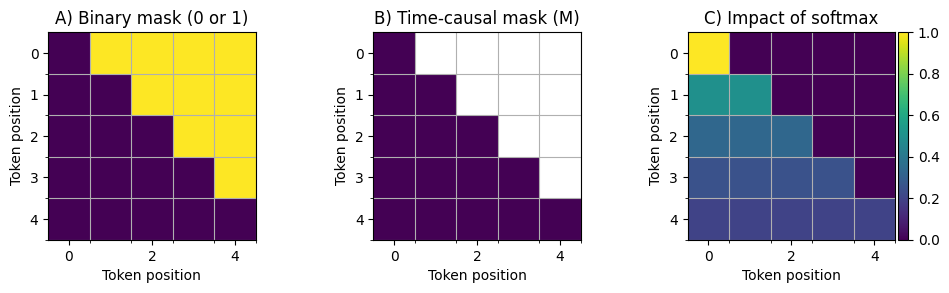

In [78]:

# create a mask with 0/1
N = 5
M = torch.triu(torch.ones(N,N),1)

# open a figure
fig,axs = plt.subplots(1,3,figsize=(10,3))

# show the mask
axs[0].imshow(M,vmin=0,vmax=1)
axs[0].set(title='A) Binary mask (0 or 1)')

# replace ones with -inf
M[M==1] = -torch.inf
axs[1].imshow(M,vmin=0,vmax=1)
axs[1].set(title='B) Time-causal mask (M)')

# impact of softmax on mask values
h = axs[2].imshow(torch.softmax(M,dim=-1),vmin=0,vmax=1)
axs[2].set(title='C) Impact of softmax')
fig.colorbar(h,ax=axs[2],pad=.01)

# adjustments for all axes
for a in axs:
  a.set(xlabel='Token position',ylabel='Token position')
  a.set_xticks(np.arange(.5,N,1),minor=True)
  a.set_yticks(np.arange(.5,N,1),minor=True)
  a.grid(which='minor')
  a.spines['top'].set_visible(True) # switched off by default, but helpful here
  a.spines['right'].set_visible(True)


plt.tight_layout()
plt.show()

## Task_2:
- Extract the Q and K matrices from layer #6, and separate into
heads using the split function. Setup a for-loop over the heads.
For each head, translate Equation 6.11 (page 328) into code (apply
the softmax transformation across the final dimension). Separate
the softmax attention scores into the three groups described above,
and concatenate them into three NumPy arrays to pool together the
results from all heads. (Hint: The self-attention scores are on the
diagonal of a tokens-by-tokens matrix.)
Visualize the results using violin plots with overlaid scatter
plots for each group, as in Figure 6.27

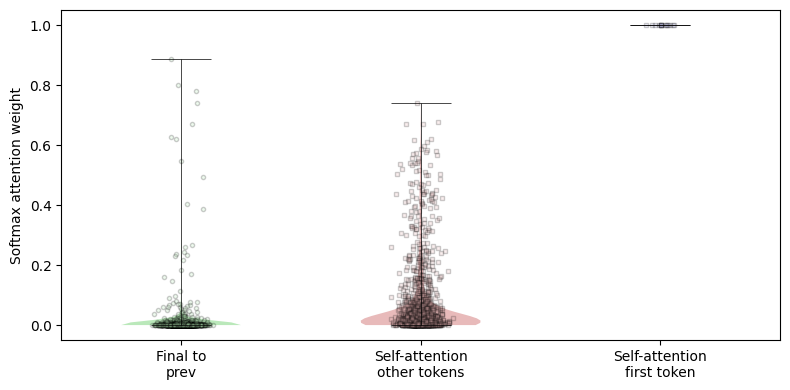

In [79]:
# get the activations
layeri = 6
Q,K,V = torch.split(activations[f'attn_L{layeri}'][0,:,:],n_emb,dim=1)
Q_h = torch.split(Q,head_dim,dim=1)
K_h = torch.split(K,head_dim,dim=1)

# empty initializations
final2prev = np.array([])
selfAttend = np.array([])
first2self = np.array([])


# loop over heads
for qi in range(n_heads):

  # raw attention scores with mask
  attn_scores = (Q_h[qi] @ K_h[qi].t()) / sqrtD
  pastmask = torch.triu(torch.ones(ntokens,ntokens),1)
  pastmask[pastmask==1] = -torch.inf
  attn_scores += pastmask


  # softmax
  attn_sm = F.softmax( attn_scores ,dim=-1)

  # the final token with all previous tokens (including the first but excluding self-attn)
  final_with_prev = attn_sm[-1,:-1]

  # matching tokens are self-attention
  matching_toks = torch.diag(attn_sm[1:,1:]) # exclude the first token in the sequence
  first_selfTok = attn_sm[0,0].unsqueeze(0)  # isolate the first token

  # add to dataset
  final2prev = np.concatenate((final2prev,final_with_prev.numpy()))
  selfAttend = np.concatenate((selfAttend,matching_toks.numpy()))
  first2self = np.concatenate((first2self,first_selfTok.numpy()))


## visualize
plt.figure(figsize=(8,4))

plt.plot(np.random.normal(1,.04,len(final2prev)),final2prev,'ko',linewidth=.1,markerfacecolor=[.7,.9,.7,.2],markersize=3)
plt.plot(np.random.normal(2,.04,len(selfAttend)),selfAttend,'ks',linewidth=.1,markerfacecolor=[.9,.7,.7,.2],markersize=3)
plt.plot(np.random.normal(3,.04,len(first2self)),first2self,'ks',linewidth=.1,markerfacecolor=[.7,.7,.9,.2],markersize=3)

v = plt.violinplot([final2prev,selfAttend,first2self])

# change the colors
v['bodies'][0].set_facecolor([.7,.9,.7])
v['bodies'][1].set_facecolor([.9,.7,.7])
v['bodies'][0].set_alpha([.9])
v['bodies'][1].set_alpha([.9])
v['cmins'].set(linewidth=.5,edgecolor='k')
v['cbars'].set(linewidth=.5,edgecolor='k')
v['cmaxes'].set(linewidth=.5,edgecolor='k')

plt.gca().set(xticks=[1,2,3],ylabel='Softmax attention weight',xlim=[.5,3.5],
              xticklabels=['Final to\nprev','Self-attention\nother tokens','Self-attention\nfirst token'])

plt.tight_layout()
plt.show()

# Part 8: Laminar softmax, self- vs. cross-attention

## Task_1:
- Repeat the histogram analysis from Part 6, while integrating the
causal attention mask and token-pair categories from Part 7, in a
for-loop over all layers. Store the histogram data in a matrix of size
24 (layers) × 3 (final to previous tokens, self-attention tokens, first
token) × 90 (histogram bins between 0 and 1).
Visualize the results in heatmaps as in Figure 6.28, where the
x-axis is the softmax probability score, the y-axis is the transformer
layer, and the color is the histogram density value. Use color limits
of 0 to .5 for all three heatmaps.

In [80]:
binedges = np.linspace(0,1,91)

attn_hists = np.zeros((n_layers,3,len(binedges)-1))


for layeri in range(n_layers):


  # empty initializations
  final2prev = np.array([])
  selfAttend = np.array([])
  first2self = np.array([])


  # get the activations
  Q,K,V = torch.split(activations[f'attn_L{layeri}'][0,:,:],n_emb,dim=1)
  Q_h = torch.split(Q,head_dim,dim=1)
  K_h = torch.split(K,head_dim,dim=1)


  # loop over heads
  for qi in range(n_heads):

    # raw attention scores with mask
    attn_scores = (Q_h[qi] @ K_h[qi].t()) / sqrtD
    pastmask = torch.tril(torch.ones(ntokens,ntokens))
    attn_scores[pastmask==0] = -torch.inf

    # softmax
    attn_sm = F.softmax( attn_scores ,dim=-1)

    # the final token with all previous tokens (including the first but excluding self-attn)
    final_with_prev = attn_sm[-1,:-1]

    # matching tokens are self-attention
    matching_toks = torch.diag(attn_sm[1:,1:]) # exclude the first token in the sequence
    first_selfTok = attn_sm[0,0].unsqueeze(0)  # isolate the first token

    # add to dataset
    final2prev = np.concatenate((final2prev,final_with_prev.numpy()))
    selfAttend = np.concatenate((selfAttend,matching_toks.numpy()))
    first2self = np.concatenate((first2self,first_selfTok.numpy()))


  # get histograms
  attn_hists[layeri,0,:],_ = np.histogram(final2prev,bins=binedges,density=True)
  attn_hists[layeri,1,:],_ = np.histogram(selfAttend,bins=binedges,density=True)
  attn_hists[layeri,2,:],_ = np.histogram(first2self,bins=binedges,density=True)



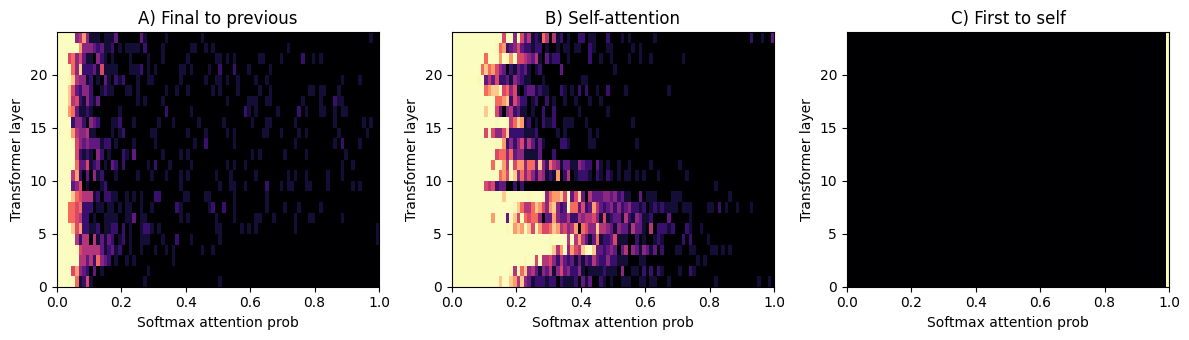

In [81]:
_,axs = plt.subplots(1,3,figsize=(12,3.5))

titels = [ 'A) Final to previous','B) Self-attention','C) First to self' ]

for i in range(3):
  axs[i].imshow(attn_hists[:,i,:],aspect='auto',origin='lower',
                extent=[binedges[0],binedges[-1],0,n_layers],vmin=0,vmax=.5,cmap='magma')
  axs[i].set(xlabel='Softmax attention prob',ylabel='Transformer layer',title=titels[i])


plt.tight_layout()
plt.show()


# Part 9: Averaging within vs. across heads

## Task_1:
- Using the Q and K matrices from one layer, calculate QK⊤ twice:
Once ignoring heads and the second time separately calculating for
each head. In the first QK⊤, scale the dot products by nh
√dh where
nh is the number of heads and dh is the head dimensionality. In the
second QK⊤, store the results in a heads × tokens × tokens tensor.
Show a scatter plot of the relationship between the ignoring
heads QK⊤ and the average of the per-head QK⊤, as in Figure
6.29A. Then show their differences as in Figure 6.29B.